In [16]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
print("Libraries imported successfully!")

Libraries imported successfully!


In [17]:
# Load the Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns = iris.feature_names
)

# Add the target column
df["species"] = iris.target

# Replace numerical class labels with flower names
df["species"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check class distribution
print("\nSpecies distribution:")
print(df["species"].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


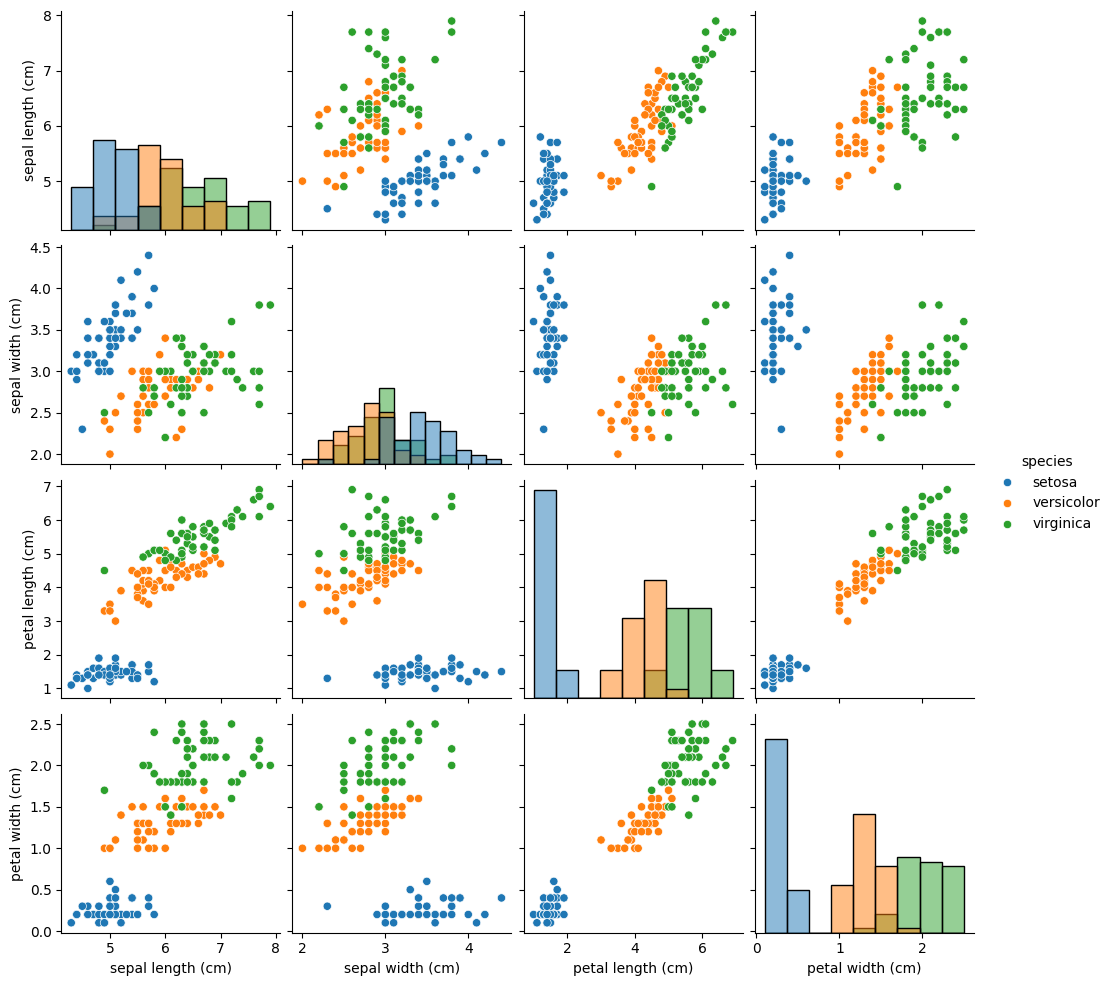

In [18]:
# Visualize relationships between flower measurements
sns.pairplot(df, hue="species", diag_kind="hist")
plt.show()

In [19]:
# Separate input features and target variable
X = df.drop("species", axis=1)
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (150, 4)
Target shape: (150,)

Feature columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Training features: (120, 4)
Testing features: (30, 4)
Training samples: 120
Testing samples: 30


In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully.")
print("Testing data scaled successfully.")
print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Training data scaled successfully.
Testing data scaled successfully.

Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [22]:
# Import classification models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Create the models
log_model = LogisticRegression(max_iter=1000, random_state=42)

tree_model = DecisionTreeClassifier(random_state=42)

# Train the Logistic Regression model
log_model.fit(X_train_scaled, y_train)

# Train the Decision Tree model
tree_model.fit(X_train_scaled, y_train)

print("Both classification models trained successfully!")

Both classification models trained successfully!


In [23]:
# Predict using Logistic Regression
y_pred_log = log_model.predict(X_test_scaled)

# Predict using Decision Tree
y_pred_tree = tree_model.predict(X_test_scaled)

print("Logistic Regression predictions:")
print(y_pred_log)

print("\nDecision Tree predictions:")
print(y_pred_tree)

Logistic Regression predictions:
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor') np.str_('virginica') np.str_('virginica')
 np.str_('virginica') np.str_('versicolor') np.str_('setosa')
 np.str_('setosa') np.str_('setosa') np.str_('versicolor')
 np.str_('versicolor') np.str_('virginica') np.str_('setosa')
 np.str_('virginica') np.str_('versicolor') np.str_('versicolor')
 np.str_('virginica') np.str_('virginica') np.str_('versicolor')
 np.str_('setosa') np.str_('virginica') np.str_('setosa')]

Decision Tree predictions:
[np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa') np.str_('versicolor')
 np.str_('setosa') np.str_('setosa') np.str_('virginica')
 np.str_('versicolor') np.str_('virginica') np.str_('virginica')
 np.str_('virginica') np.str_('versicolor') np.str_('setosa')
 np.str_

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate metrics for Logistic Regression
log_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_log),
    "Precision": precision_score(y_test, y_pred_log, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, y_pred_log, average="weighted", zero_division=0),
    "F1-score": f1_score(y_test, y_pred_log, average="weighted", zero_division=0)
}

# Calculate metrics for Decision Tree
tree_metrics = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred_tree),
    "Precision": precision_score(y_test, y_pred_tree, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, y_pred_tree, average="weighted", zero_division=0),
    "F1-score": f1_score(y_test, y_pred_tree, average="weighted", zero_division=0)
}

# Display the comparison table
results = pd.DataFrame([log_metrics, tree_metrics])

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


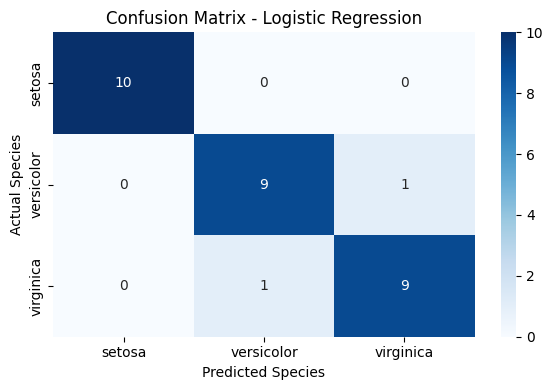

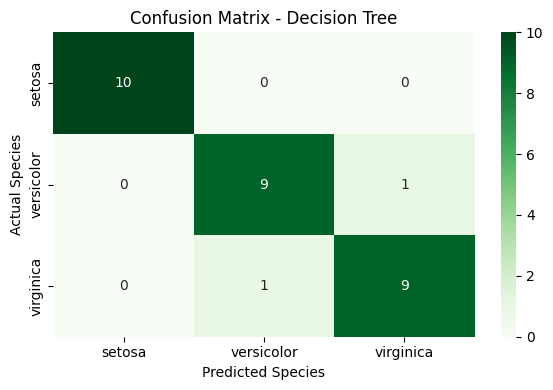

In [25]:
from sklearn.metrics import confusion_matrix

class_names = list(iris.target_names)

# Logistic Regression confusion matrix
cm_log = confusion_matrix(
    y_test, y_pred_log, labels=class_names
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

# Decision Tree confusion matrix
cm_tree = confusion_matrix(
    y_test, y_pred_tree, labels=class_names
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

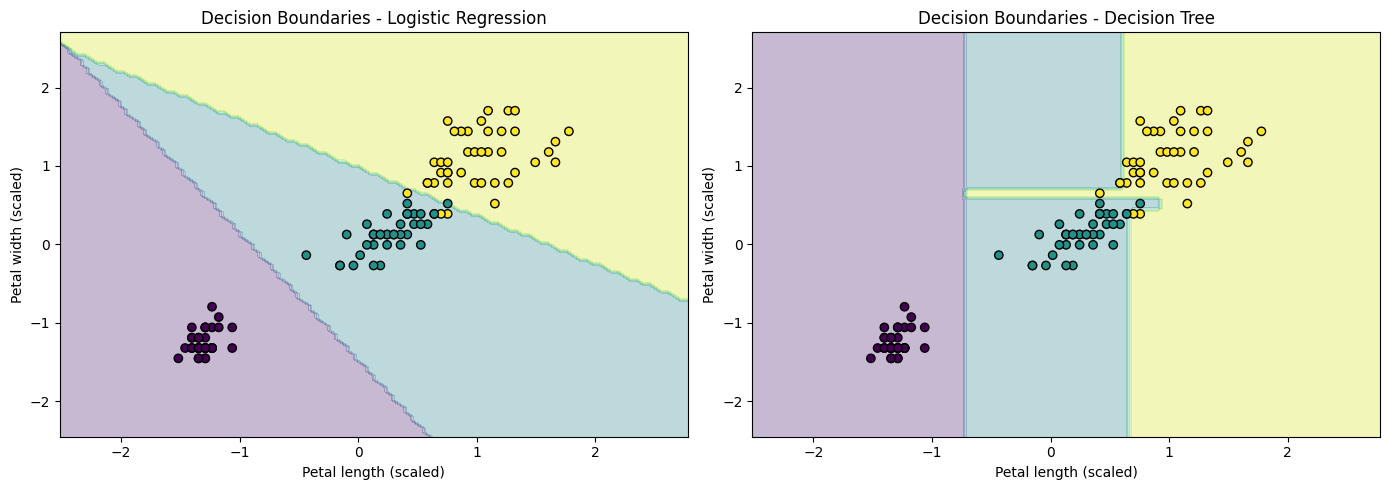

In [26]:
from sklearn.inspection import DecisionBoundaryDisplay

# Use two features for a 2D visualization
X_2d = X[["petal length (cm)", "petal width (cm)"]]

# Split the same two features using the existing training/test indices
X_train_2d = X_2d.loc[X_train.index]
X_test_2d = X_2d.loc[X_test.index]

# Scale using training data only
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Train models using the two selected features
log_2d = LogisticRegression(max_iter=1000, random_state=42)
tree_2d = DecisionTreeClassifier(random_state=42)

log_2d.fit(X_train_2d_scaled, y_train)
tree_2d.fit(X_train_2d_scaled, y_train)

# Plot decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in zip(
    axes,
    [log_2d, tree_2d],
    ["Logistic Regression", "Decision Tree"]
):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d_scaled,
        response_method="predict",
        xlabel="Petal length (scaled)",
        ylabel="Petal width (scaled)",
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X_train_2d_scaled[:, 0],
        X_train_2d_scaled[:, 1],
        c=pd.Categorical(y_train, categories=iris.target_names).codes,
        edgecolor="black"
    )

    ax.set_title(f"Decision Boundaries - {title}")

plt.tight_layout()
plt.show()

# Multi-Class Benchmark Classification Pipeline

## 1. Objective
The objective of this project is to build and compare multi-class classification models using the Iris dataset.

## 2. Dataset
The Iris dataset contains 150 observations, four numerical flower measurements, and three target classes: setosa, versicolor, and virginica.

## 3. Methodology
- Loaded and inspected the dataset using Pandas.
- Performed exploratory data analysis using a Seaborn pairplot.
- Split the data into 80% training and 20% testing sets.
- Applied StandardScaler to standardize the input features.
- Trained Logistic Regression and Decision Tree classifiers.
- Evaluated both models using accuracy, weighted precision, weighted recall, and weighted F1-score.
- Visualized confusion matrices and decision boundaries.

## 4. Results
The evaluation metrics are displayed in the model comparison table above. The confusion matrices show the correct and incorrect predictions for each species.

## 5. Findings
Compare the accuracy, precision, recall, and F1-score of both models. The model with stronger evaluation scores performed better on this particular test split. The confusion matrices help identify which species were classified correctly or confused with another class.

## 6. Conclusion
This project demonstrates a complete multi-class classification workflow, from data exploration and preprocessing to model training, evaluation, and visualization. Comparing two algorithms helps illustrate how different classification methods perform on the same dataset.